# 기존 CNN에서 무엇이 추가되었나? — TEP 기능 확장 종합 안내

**이 노트북의 목적은 기존 모델과 추가 연구의 차이를 쉽게 설명하는 것입니다.**
기존 CNN은 원래 정상(0)·Fault 1~20의 **21개 클래스 확률**을 출력했습니다. 이번 작업은 그 출력을 재사용하여 유형별 진단을 독립적으로 검증하고, 센서 입력 가용성 저하에 따른 검출·진단의 차이를 분석했습니다. 여기에 **별도의 LSTM 다음 시점 공정 변수 예측기**를 추가했습니다.

기존 CNN의 구조·가중치·입력·경보 임계값과 기존 노트북은 유지했습니다. LSTM만 새로 학습했으며 LSTM 예측값을 CNN에 연결하지 않았습니다.

작성 기준: 2026-11-12. 아래 표와 그림은 저장된 실제 평가 산출물을 읽습니다. **이 노트북을 다시 실행해도 모델 학습이나 대규모 Test 추론을 하지 않습니다.** 실행 결과와 그림은 노트북 안에도 포함됩니다.

읽는 순서: **기능 비교 → 전체 구조 → 기존 성능 → 유형 진단 → 입력 가용성 → LSTM → 사용 방법과 한계**.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'reports/fault_type_validation/validation.json').exists()), None)
assert ROOT is not None, 'TEP 프로젝트 안에서 실행하세요.'
D = ROOT / 'reports/fault_type_validation'
F = ROOT / 'reports/next_step_forecasting'
A = ROOT / 'reports/sensor_availability'
def read(folder, filename): return pd.read_csv(folder / 'tables' / filename)
def picture(folder, filename): display(Image(filename=str(folder / 'figures' / filename)))
v = json.loads((D / 'validation.json').read_text(encoding='utf-8'))
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False})
display(Markdown('**데이터 준비 완료:** 기존 평가표와 그림을 읽었습니다.'))

**데이터 준비 완료:** 기존 평가표와 그림을 읽었습니다.

## 1. 기능을 기준으로 본 변경 사항

**새로운 CNN 분류 출력을 만든 것이 아닙니다.** 기존 출력의 의미를 구분하고, 실제로 얼마나 정확하게 고장 유형을 판단하는지 평가와 시각화를 추가했습니다. 아래의 ‘추가’는 평가 기능인지 새 모델인지 구분해서 읽어야 합니다.

In [2]:
features = pd.DataFrame([
 ['정상 / 고장 판단', '기존 기능', '유지', '고정 CNN·기존 경보 임계값 재사용'],
 ['정상 0 / Fault 1~20 확률', '기존 21개 출력에 포함', '기존 출력 재사용', '21개 확률에서 정상 여부와 유형 후보 산출'],
 ['유형별 Precision / Recall / F1', '기존 출력으로 계산 가능', '독립 평가 추가', 'Fault별 성능표·혼동행렬·오분류 확인'],
 ['실행 단위 유형 진단', '기존 검출 지연 분석을 확장', '평가 규칙·결과 추가', '동일 유형 3연속 확정·최초 유형 정확도·정답 진단 지연'],
 ['입력 가용성 영향', '검출 영향 연구 수행', '진단까지 비교 확장', '전체 / 가용 실행 분모로 검출과 정답 진단 비교'],
 ['다음 시점 공정 변수 예측', '별도 기능 없음', '새 LSTM 모델 추가', '과거 20×52 → 3분 뒤 52개 변수'],
 ['LSTM 예측으로 CNN 성능 개선', '없음', '이번 구현 범위에 포함되지 않음', '두 모델은 별도 경로로 동작']
], columns=['기능', '기존 상태', '이번 변경', '제공 결과'])
display(features.style.hide(axis='index'))

기능,기존 상태,이번 변경,제공 결과
정상 / 고장 판단,기존 기능,유지,고정 CNN·기존 경보 임계값 재사용
정상 0 / Fault 1~20 확률,기존 21개 출력에 포함,기존 출력 재사용,21개 확률에서 정상 여부와 유형 후보 산출
유형별 Precision / Recall / F1,기존 출력으로 계산 가능,독립 평가 추가,Fault별 성능표·혼동행렬·오분류 확인
실행 단위 유형 진단,기존 검출 지연 분석을 확장,평가 규칙·결과 추가,동일 유형 3연속 확정·최초 유형 정확도·정답 진단 지연
입력 가용성 영향,검출 영향 연구 수행,진단까지 비교 확장,전체 / 가용 실행 분모로 검출과 정답 진단 비교
다음 시점 공정 변수 예측,별도 기능 없음,새 LSTM 모델 추가,과거 20×52 → 3분 뒤 52개 변수
LSTM 예측으로 CNN 성능 개선,없음,이번 구현 범위에 포함되지 않음,두 모델은 별도 경로로 동작


## 2. 현재 시스템의 전체 구조

입력은 동일한 52개 센서 변수의 연속 관측입니다. **CNN은 현재 상태를 판단**하고, **LSTM은 다음 관측값을 예측**합니다. 고장 유형 진단은 미래에 어떤 고장이 날지 맞히는 기능과 다릅니다. 센서 입력이 없는 시점에는 임의의 정상·고장 예측을 만들지 않습니다.

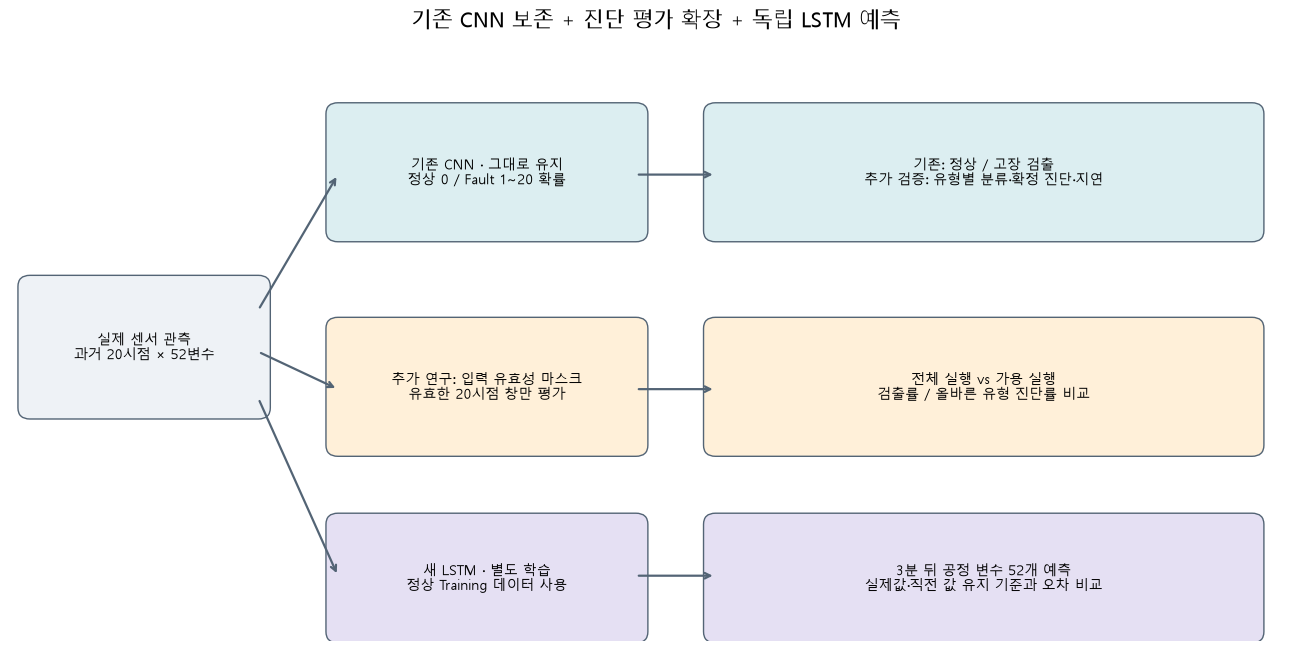

In [3]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(13, 6.4), layout='constrained')
ax.set(xlim=(0, 13), ylim=(0, 6.4)); ax.axis('off')
def box(x, y, w, h, text, color):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.12',
                               facecolor=color,edgecolor='#536475'))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=10)
def arrow(x1,y1,x2,y2):
    ax.annotate('',xy=(x2,y2),xytext=(x1,y1),arrowprops=dict(arrowstyle='->',color='#536475',lw=1.6))
box(.2,2.5,2.3,1.3,'실제 센서 관측\n과거 20시점 × 52변수','#eef2f6')
box(3.3,4.4,3.0,1.25,'기존 CNN · 그대로 유지\n정상 0 / Fault 1~20 확률','#dceef1')
box(7.1,4.4,5.4,1.25,'기존: 정상 / 고장 검출\n추가 검증: 유형별 분류·확정 진단·지연','#dceef1')
box(3.3,2.1,3.0,1.25,'추가 연구: 입력 유효성 마스크\n유효한 20시점 창만 평가','#fff0d9')
box(7.1,2.1,5.4,1.25,'전체 실행 vs 가용 실행\n검출률 / 올바른 유형 진단률 비교','#fff0d9')
box(3.3,.1,3.0,1.15,'새 LSTM · 별도 학습\n정상 Training 데이터 사용','#e5e0f3')
box(7.1,.1,5.4,1.15,'3분 뒤 공정 변수 52개 예측\n실제값·직전 값 유지 기준과 오차 비교','#e5e0f3')
arrow(2.5,3.55,3.3,5); arrow(2.5,3.1,3.3,2.7); arrow(2.5,2.6,3.3,.7)
arrow(6.3,5,7.1,5); arrow(6.3,2.7,7.1,2.7); arrow(6.3,.7,7.1,.7)
ax.set_title('기존 CNN 보존 + 진단 평가 확장 + 독립 LSTM 예측',fontsize=15,pad=12)
plt.show()

## 3. 재사용한 데이터와 기존 CNN

Harvard TEP의 52개 변수(측정 변수 41개·조작 변수 11개), 관측 간격 3분을 사용했습니다. 원래의 실행 family 기준 Train 400 / Validation 100 / Test 500 분할을 유지했습니다. CNN의 입력은 20×52이며, 과거 관측만 사용하고 실행 경계를 넘지 않습니다.

고정 모델은 `CNN1D_Temporal_balanced_s42`입니다. 기존 Test 결과 재현을 확인한 뒤 추가 평가를 수행했습니다. **아래의 시점 단위 지표와 실행 단위 검출률은 분모가 다릅니다.** 정상 실행에서의 경보 부담도 정상 시점의 오탐 비율과 구분합니다.

In [4]:
baseline = read(A, 'baseline_reproduction.csv')
display(baseline)
display(pd.DataFrame([
 ['CNN 고정 경보 임계값', v['threshold']],
 ['CNN Test 평가 시점 수', v['samples']],
 ['고장 주입 이후 시점 수', v['post_fault_samples']],
 ['Test 고장 실행 수', 10000],
 ['실행 단위 검출 성공', '9,851 / 10,000 (98.51%)'],
 ['성공 실행의 검출 지연 중앙값', '48분'],
 ['정상 실행 경보 부담', '500개 정상 실행, 23,525시간에 705회 경보 episode'],
 ['정상 실행 시간당 경보 episode', '약 0.02997회 / 시간']
], columns=['항목', '결과']).style.hide(axis='index'))

,metric,expected,reproduced,absolute_error,passed
0,detection_roc_auc,0.9539266359692902,0.9539266359692902,0.0,True
1,detection_f1,0.9276972980979862,0.9276972980979862,0.0,True
2,detection_precision,0.9970010449576019,0.9970010449576019,0.0,True
3,detection_recall,0.86740225,0.86740225,0.0,True
4,sample_false_alarm_rate,0.011099707524594523,0.011099707524594523,0.0,True
5,per_event_detected,10000 original records,10000 fresh records,0.0,True
6,per_event_first_detection_sample,10000 original records,10000 fresh records,0.0,True
7,per_event_delay_minutes,10000 original records,10000 fresh records,0.0,True
8,normal_alarm_episodes,705.0,705,0.0,True
9,normal_exposure_hours,23525.0,23525.0,0.0,True


항목,결과
CNN 고정 경보 임계값,0.967192
CNN Test 평가 시점 수,9880500
고장 주입 이후 시점 수,8000000
Test 고장 실행 수,10000
실행 단위 검출 성공,"9,851 / 10,000 (98.51%)"
성공 실행의 검출 지연 중앙값,48분
정상 실행 경보 부담,"500개 정상 실행, 23,525시간에 705회 경보 episode"
정상 실행 시간당 경보 episode,약 0.02997회 / 시간


## 4. 추가 검증 ① — 고장 유형 분류

동일한 21개 확률을 세 가지 방식으로 평가했습니다.

| 평가 방식 | 판단 방법 | 해석 |
|---|---|---|
| 단순 21종 argmax | 정상 포함 가장 큰 확률의 클래스 | 기존 경보 임계값을 쓰지 않는 비교 평가 |
| 경보 임계값 적용 21종 | 고장 확률이 임계값 이상이면 Fault 1~20 후보, 아니면 정상 | 검출 실패까지 포함한 운영 규칙의 시점별 분류 |
| 고장 조건부 20종 | 실제 고장 구간에서 Fault 1~20 중 선택 | 고장 상태라는 정보를 알고 있다고 가정한 유형 구분 능력 |

**조건부 20종 F1을 전체 운영 진단 성능으로 해석하면 안 됩니다.** 모델이 정상으로 판단해 고장을 놓치는 문제는 임계값 적용 21종 평가에서 함께 반영됩니다. Macro-F1은 각 클래스 F1의 단순 평균입니다.

평가 방식,Accuracy,Macro Precision,Macro Recall,Macro F1
단순 21종 argmax,0.8311,0.8792,0.8767,0.8700
임계값 적용 21종,0.8732,0.8698,0.8529,0.8558
고장 조건부 20종,0.9136,0.9236,0.9136,0.9115


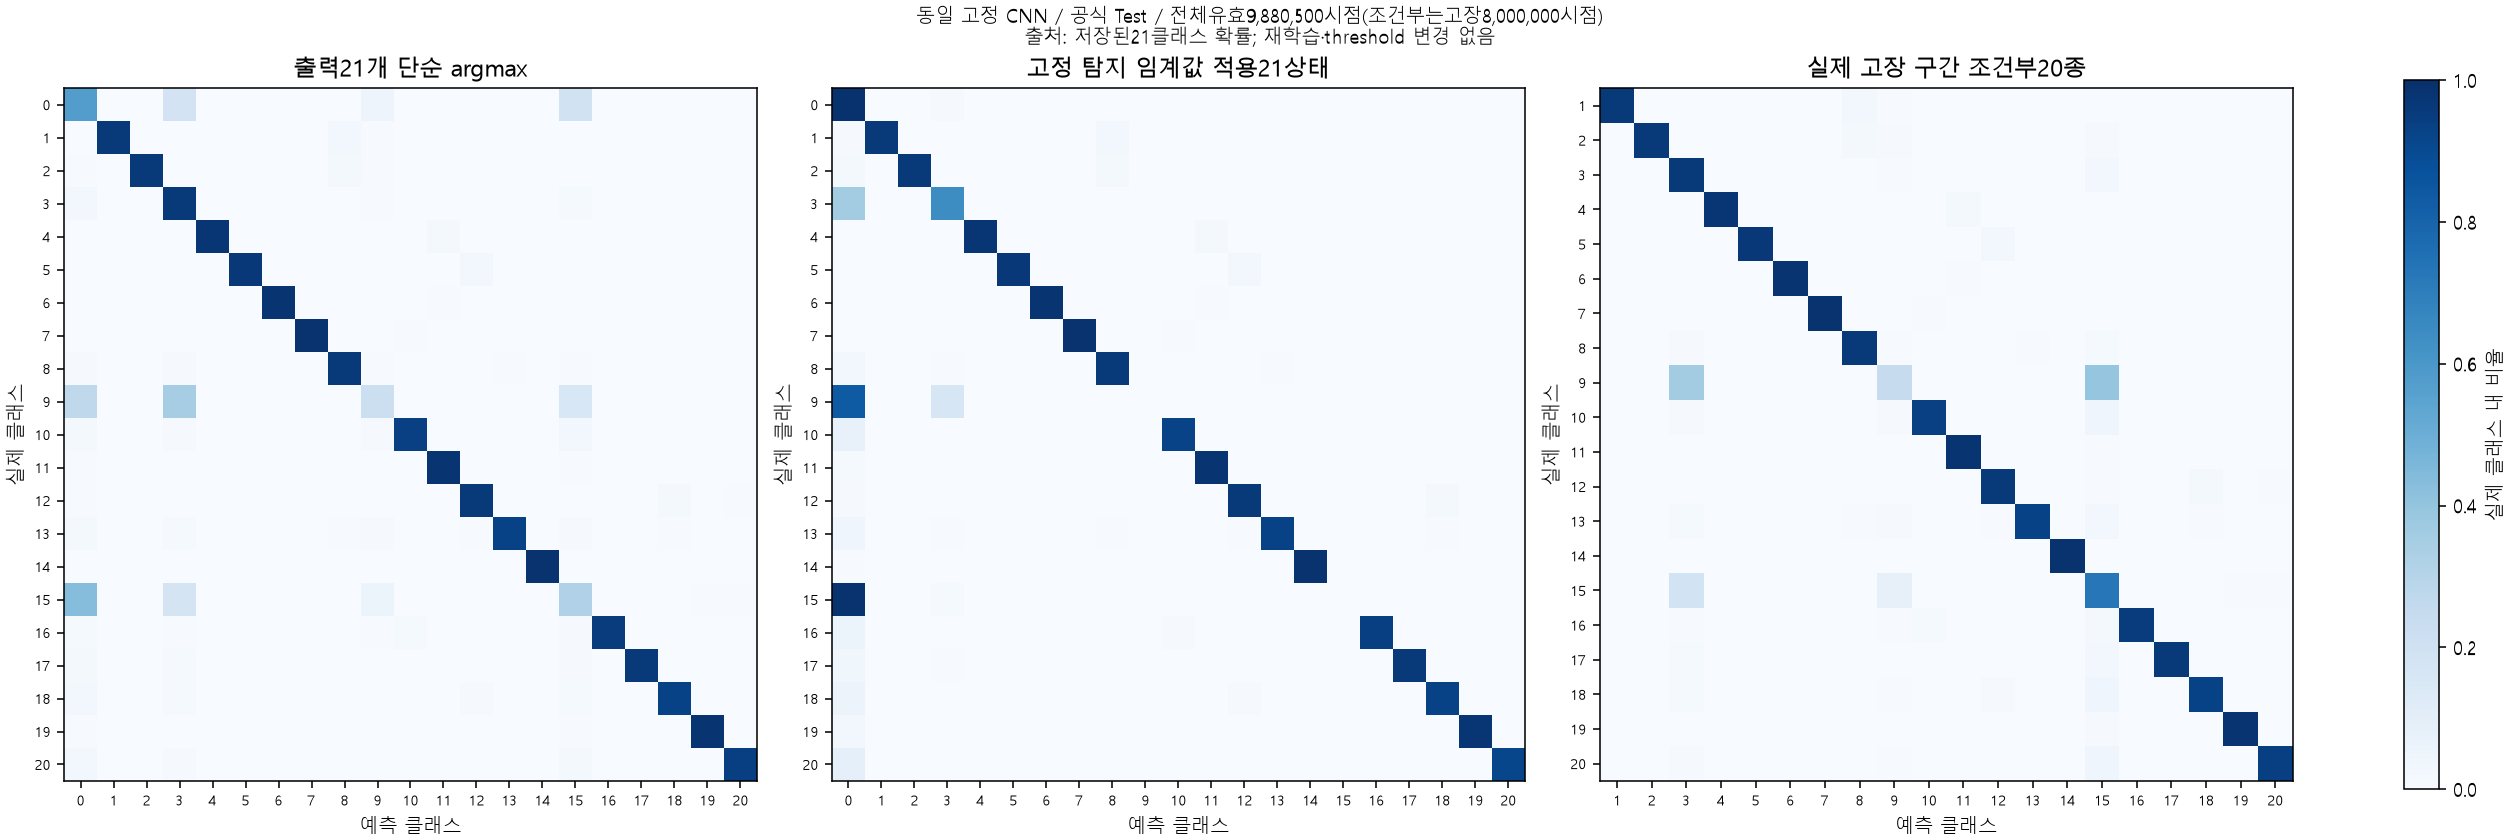

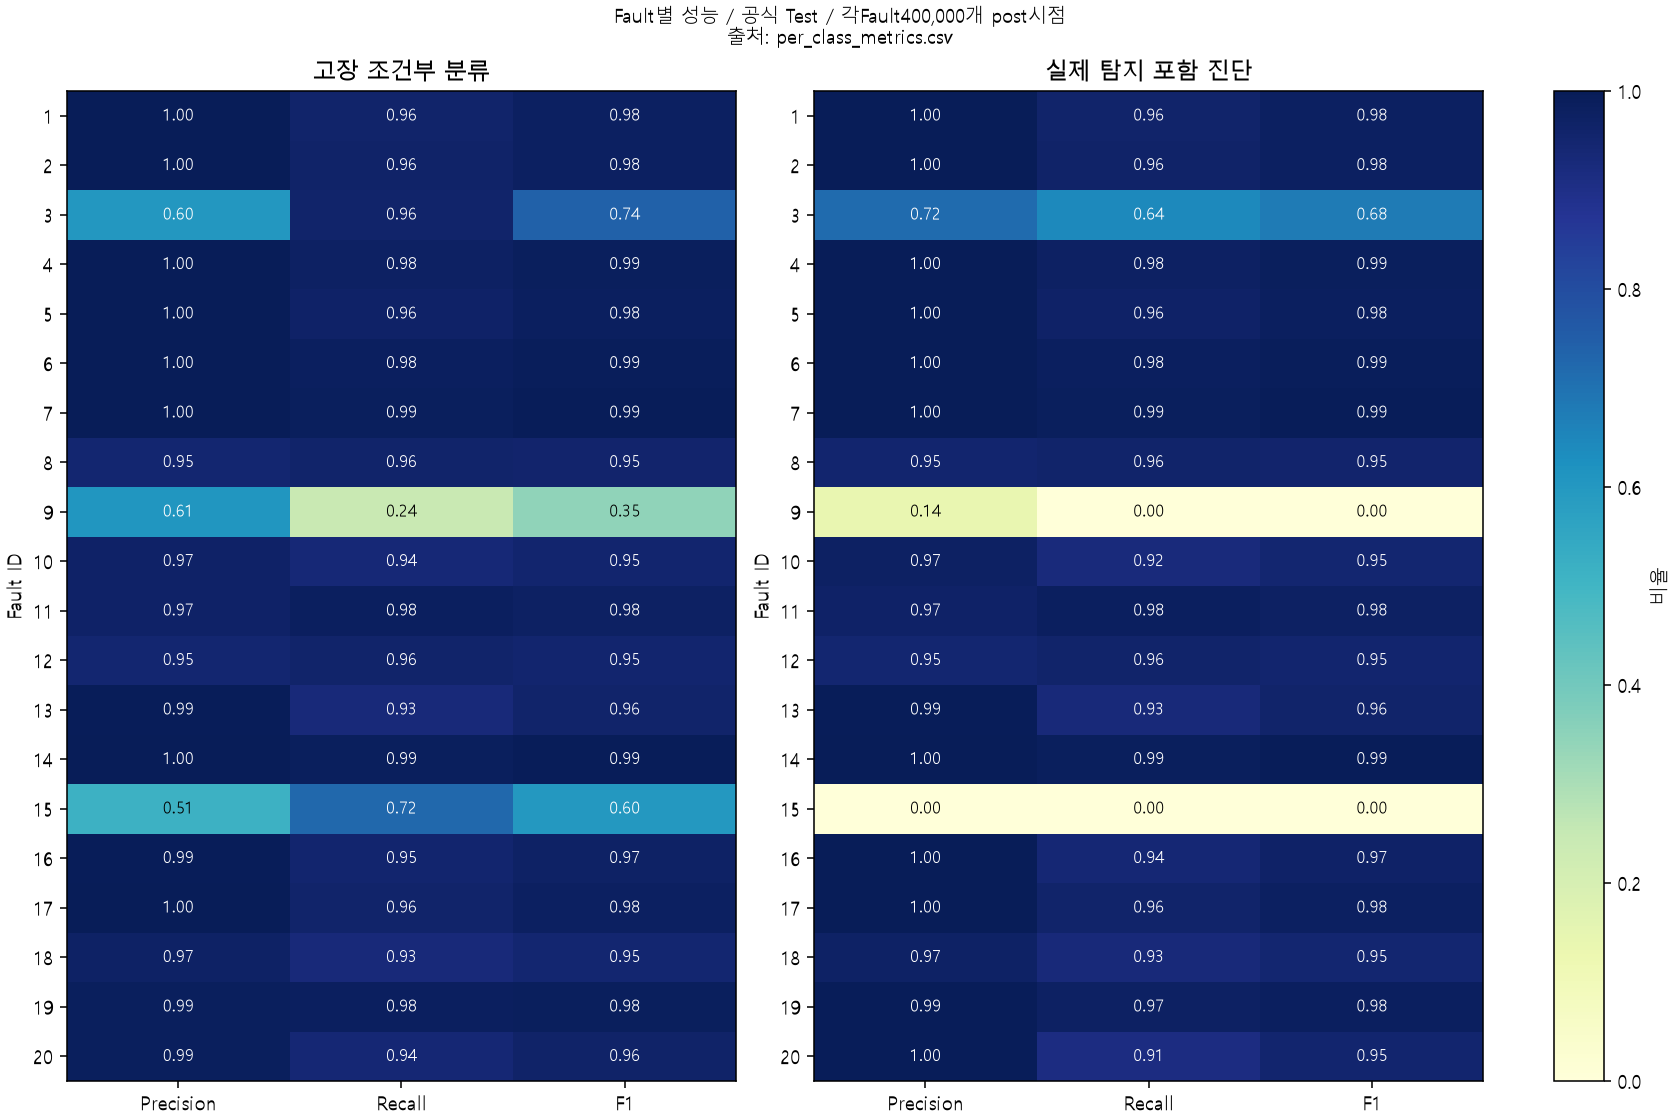

In [5]:
classification = read(D, 'classification_summary.csv').copy()
classification['mode'] = classification['mode'].replace({
 'argmax21':'단순 21종 argmax','gated21':'임계값 적용 21종','conditional20':'고장 조건부 20종'})
classification.columns = ['평가 방식','Accuracy','Macro Precision','Macro Recall','Macro F1']
display(classification.style.format({c:'{:.4f}' for c in classification.columns[1:]}).hide(axis='index'))
picture(D, 'confusions_three_definitions.png')
picture(D, 'per_fault_classification.png')

### 시점별 결과는 어떻게 읽나?

`p_fault = 1 - p_normal`입니다. 경보 임계값을 통과하지 못한 시점은 유형 후보의 확률이 커도 정상으로 처리합니다. `conditional_candidate`는 고장이라고 가정했을 때의 후보이고, `gated_type`은 실제 임계값을 반영한 시점별 판단입니다. `gated_type` 한 번만으로 3연속 확정 진단이 되는 것은 아닙니다. 아래는 Test에서 추출한 실제 예입니다.

In [6]:
examples = read(D, 'prediction_examples.csv')
display(examples[['actual','scenario','run','sample','fault_probability',
                  'conditional_candidate','gated_type','top3_types']].head(16)
        .rename(columns={'actual':'실제 클래스','scenario':'고장 시나리오','run':'실행',
                         'sample':'시점','fault_probability':'고장 확률',
                         'conditional_candidate':'조건부 유형 후보','gated_type':'임계값 반영 판단',
                         'top3_types':'유형 후보 상위 3개'}))

,실제 클래스,고장 시나리오,실행,시점,고장 확률,조건부 유형 후보,임계값 반영 판단,유형 후보 상위 3개
0,0,0,1,20,0.614271,15,0,"15,9,18"
1,0,0,1,160,0.746685,15,0,"15,9,3"
2,0,0,1,161,0.812568,3,0,"3,15,9"
3,0,0,1,200,0.654190,15,0,"15,9,18"
4,0,0,1,400,0.673867,15,0,"15,9,18"
5,0,0,1,960,0.770176,9,0,"9,15,3"
6,0,1,1,20,0.614271,15,0,"15,9,18"
7,0,1,1,160,0.746685,15,0,"15,9,3"
8,1,1,1,161,0.760296,15,0,"15,3,9"
9,1,1,1,200,1.000000,1,1,"1,8,18"


## 5. 추가 검증 ② — 검출과 올바른 진단을 분리

**검출**은 ‘고장이다’, **진단**은 ‘어떤 고장이다’를 판단하는 것입니다.

- 검출: 고장 주입 이후 기존 임계값을 통과한 상태가 3시점 연속 발생.
- 유형 확정: 임계값을 통과한 동일한 비정상 유형이 3시점 연속 발생.
- 최초 유형 정확도: 유형이 한 번이라도 확정된 실행 중 첫 확정 유형이 정답인 비율.
- 올바른 진단 성공: 관측 기간 안에 정답 유형의 확정 구간이 한 번이라도 발생. 정답은 평가에만 사용.

지연은 주입 시점에서 3연속 조건이 확인된 시점까지의 시간입니다. **나중에 정답을 맞힌 것과 처음부터 정답을 맞힌 것은 다릅니다.** 정답 진단이 한 번 나타난 뒤 지속적으로 유지되는지까지 보장하는 지표도 아닙니다.

,항목,결과
0,고장 실행,10000.000000
1,한번이라도 고장 검출,9851.000000
2,올바른 유형3연속 진단,9015.000000
3,최초 유형 확정 실행,9848.000000
4,최초 확정 유형이 정답,4417.000000
5,최초 유형 정확도(유형 확정 실행 분모),0.448517
6,올바른 진단 성공 실행 지연 중앙값(분),69.000000
7,검출~올바른 진단 추가 지연의 중앙값(분),12.000000


,Fault,실행 수,검출 실행,정답 진단 실행,검출률,정답 진단률,최초 유형 정확도,검출 지연 중앙값(분),정답 진단 지연 중앙값(분),추가 지연 중앙값(분)
0,1,500,500,500,1.000,1.00,0.000,33.0,105.0,72.0
1,2,500,500,500,1.000,1.00,0.000,54.0,102.0,45.0
2,3,500,500,500,1.000,1.00,0.990,54.0,54.0,0.0
3,4,500,500,500,1.000,1.00,0.000,12.0,69.0,57.0
4,5,500,500,500,1.000,1.00,0.000,18.0,93.0,75.0
5,6,500,500,500,1.000,1.00,0.000,15.0,51.0,36.0
6,7,500,500,500,1.000,1.00,0.134,18.0,30.0,12.0
7,8,500,500,500,1.000,1.00,0.406,69.0,84.0,12.0
8,9,500,500,15,1.000,0.03,0.000,187.5,1362.0,906.0
9,10,500,500,500,1.000,1.00,0.958,87.0,90.0,0.0


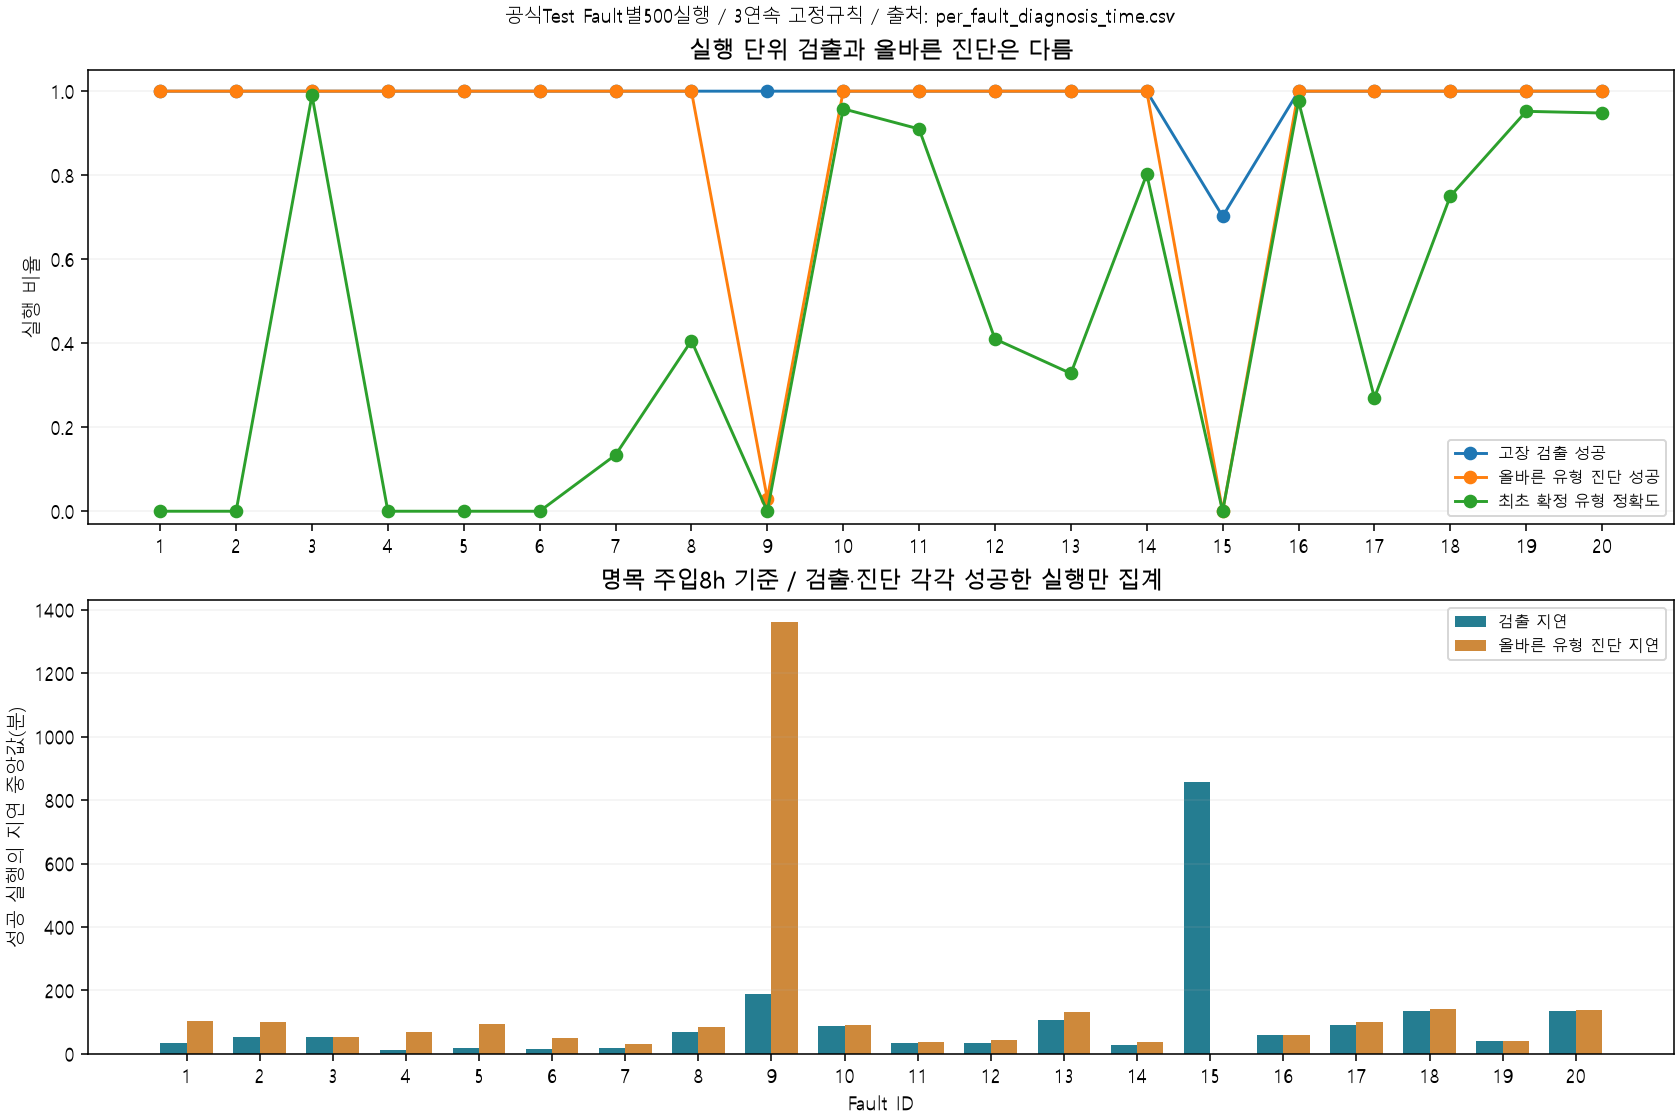

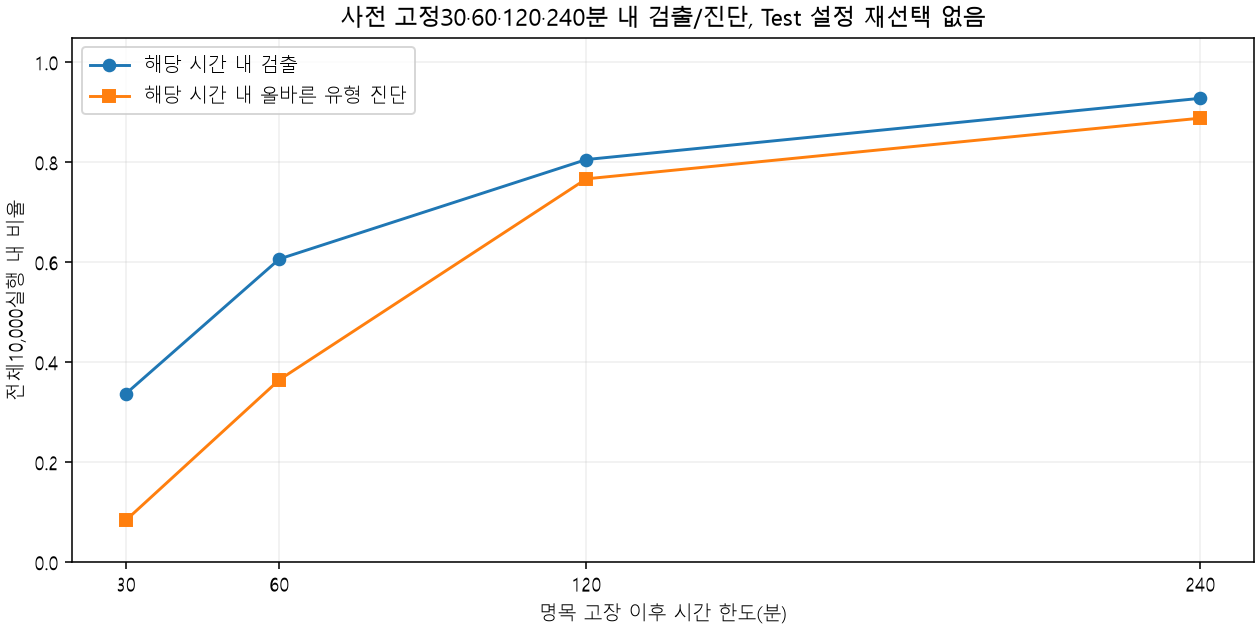

In [7]:
display(read(D, 'run_summary.csv'))
timing = read(D, 'per_fault_diagnosis_time.csv')
display(timing.rename(columns={
 'fault':'Fault','runs':'실행 수','detected_runs':'검출 실행','correct_diagnosis_runs':'정답 진단 실행',
 'run_detection_rate':'검출률','run_correct_diagnosis_rate':'정답 진단률',
 'first_type_accuracy':'최초 유형 정확도','detection_delay_median':'검출 지연 중앙값(분)',
 'correct_diagnosis_delay_median':'정답 진단 지연 중앙값(분)',
 'additional_diagnosis_delay_median':'추가 지연 중앙값(분)'}))
picture(D, 'detection_vs_diagnosis_time.png')
picture(D, 'early_correct_diagnosis.png')

**해석:** 실행 검출률은 98.51%지만 정답 유형 진단률은 90.15%입니다. 최초 확정 유형 정확도는 44.85%여서 초기 과도 구간의 유형 혼동이 큽니다. Fault 9는 500개 모두 검출했지만 정답 진단은 15개(3%)였고, Fault 15는 정답 진단이 없었습니다.

정답 진단 지연 중앙값 69분은 정답 진단에 성공한 실행만의 통계입니다. 검출 지연 48분과 모집단이 다르므로 단순 차이 21분을 추가 진단 시간으로 해석하지 않습니다. 동일 실행끼리 계산한 추가 지연 중앙값은 12분입니다. 실패 실행을 제외한 지연만 보고 성능이 좋다고 결론내리지 않도록 성공률을 함께 제시합니다.

## 6. 추가 검증 ③ — 입력 가용성이 검출과 진단에 미치는 영향

0%, 10%, 25%, 40%, 53.1%는 **전체 센서 샘플의 삭제 비율이 아니라, 고장 실행 중 입력 부족으로 평가 불가능하게 만드는 실행 비율**입니다. 고장 유형별로 균형을 맞추고 누락 seed 42·43·44를 반복했습니다.

선택 실행에서 원본 sample 141~960의 연속 센서 구간을 누락시켜 고장 이후 유효한 20시점 입력 창이 하나도 남지 않게 했습니다. 미래값 보간이나 임의 예측은 사용하지 않았습니다. 원본 확률 중 유효한 창만 선택하는 방법과 실제 누락 입력의 유효 창 평가가 동등한지도 검증했습니다.

| 지표 | 분모 |
|---|---|
| 전체 검출률 / 전체 정답 진단률 | 전체 고장 실행 10,000개 |
| 조건부 검출률 / 조건부 정답 진단률 | 유효한 고장 이후 입력이 하나라도 있는 실행 |

아래 값은 세 누락 seed의 **실제 측정 평균**입니다. 실행 수의 소수점은 반복 평균이므로 생기며, 개별 실험에서 실행을 소수 개 사용한 것이 아닙니다.

입력 불가 비율,가용 실행,입력 불가 실행,검출 실행 평균,정답 진단 실행 평균,전체 검출률,조건부 검출률,전체 정답 진단률,조건부 정답 진단률
0.00%,"10,000.00",0.00,"9,851.00","9,015.00",98.51%,98.51%,90.15%,90.15%
10.00%,"9,000.00","1,000.00","8,864.00","8,114.00",88.64%,98.49%,81.14%,90.16%
25.00%,"7,500.00","2,500.00","7,383.00","6,761.33",73.83%,98.44%,67.61%,90.15%
40.00%,"6,000.00","4,000.00","5,906.67","5,409.33",59.07%,98.44%,54.09%,90.16%
53.10%,"4,690.00","5,310.00","4,617.33","4,228.67",46.17%,98.45%,42.29%,90.16%


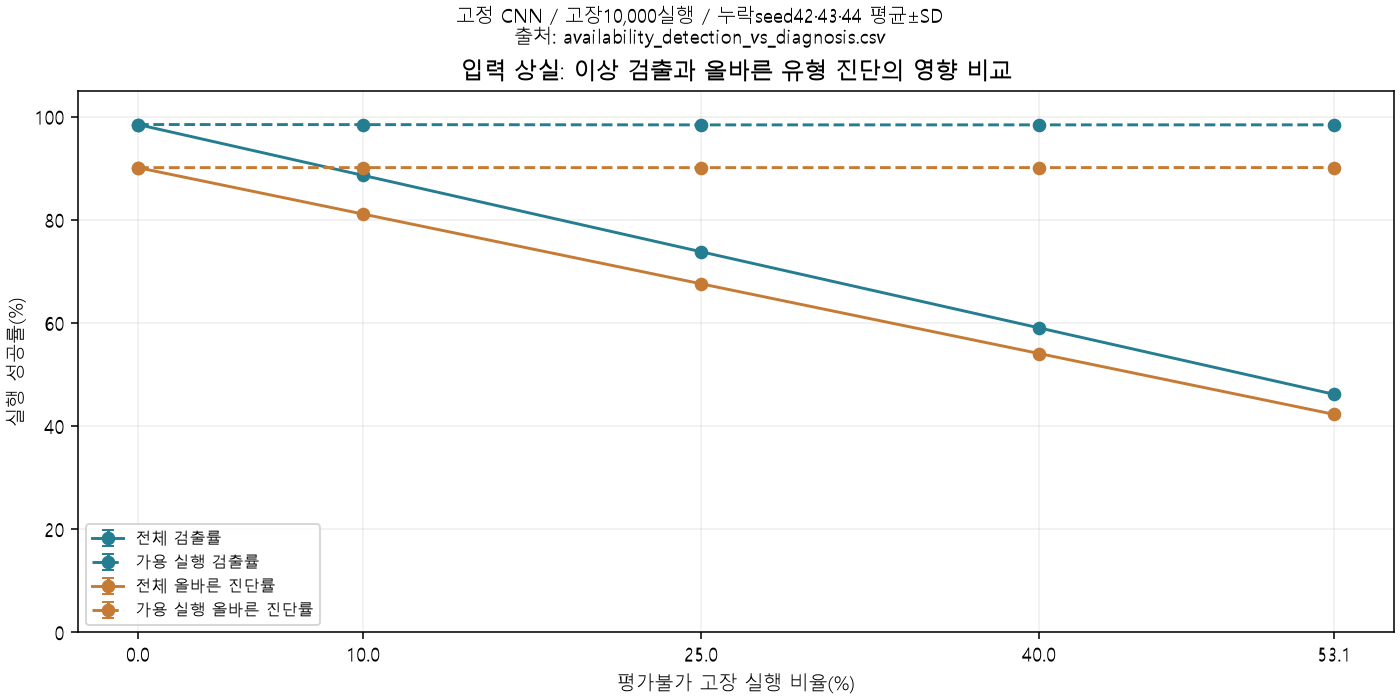

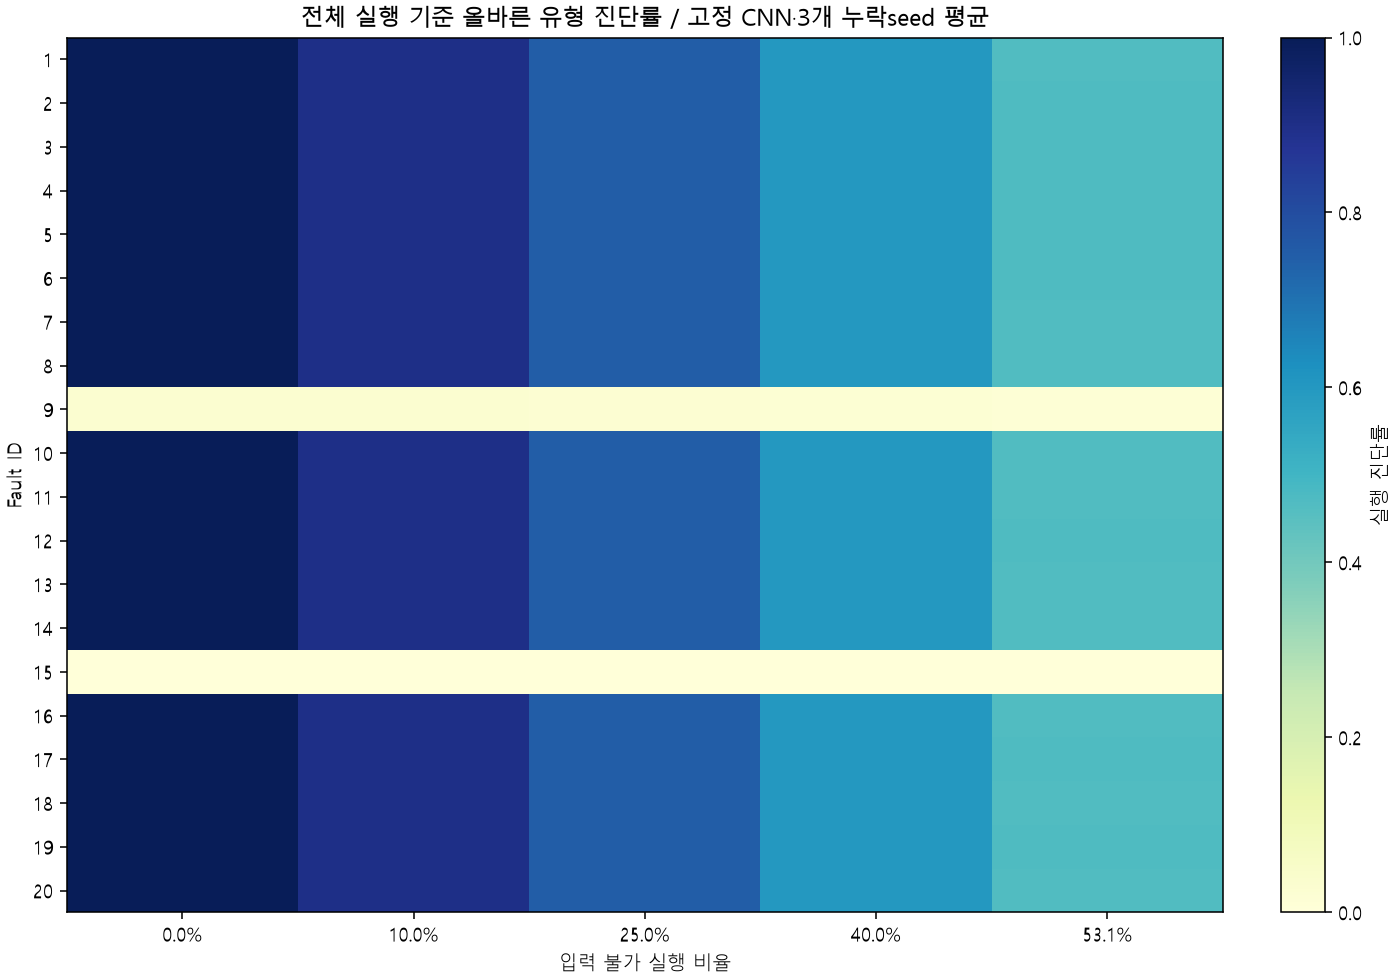

In [8]:
av = read(D, 'availability_mean.csv')
av_show = av[['rate','available_runs','unavailable_runs','detected_runs','correct_diagnosis_runs',
             'overall_detection_rate','conditional_detection_rate',
             'overall_correct_diagnosis_rate','conditional_correct_diagnosis_rate']].copy()
av_show.columns = ['입력 불가 비율','가용 실행','입력 불가 실행','검출 실행 평균','정답 진단 실행 평균',
                   '전체 검출률','조건부 검출률','전체 정답 진단률','조건부 정답 진단률']
formats = {c:'{:.2%}' for c in av_show.columns if '비율' in c or '률' in c}
formats.update({c:'{:,.2f}' for c in av_show.columns if c not in formats})
display(av_show.style.format(formats).hide(axis='index'))
picture(D, 'availability_detection_vs_diagnosis.png')
picture(D, 'availability_per_fault_diagnosis.png')

### 성능 감소의 원인을 분리해서 보기

**A. 입력 자체가 없어 판단하지 못함**과 **B. 입력은 있었지만 판단에 실패함**을 분리합니다. 진단에서는 B 안에 ‘고장도 검출하지 못함’과 ‘고장은 검출했으나 정답 유형 확정은 실패함’이 포함됩니다. 다음 분해는 앞서 측정한 실행 수의 차이로 계산한 집계이며 별도의 추론 실험이 아닙니다.

In [9]:
decomp = pd.DataFrame({
 '입력 불가 비율': av.rate,
 'A: 입력 없음': av.unavailable_runs,
 'B1: 입력 있으나 검출 실패': av.available_runs-av.detected_runs,
 'B2: 검출했으나 정답 진단 실패': av.detected_runs-av.correct_diagnosis_runs,
 '정답 진단 성공': av.correct_diagnosis_runs})
assert np.allclose(decomp.iloc[:,1:].sum(axis=1), 10000)
display(decomp.style.format({'입력 불가 비율':'{:.1%}', **{c:'{:,.2f}' for c in decomp.columns[1:]}}).hide(axis='index'))
partial = json.loads((A/'tables/summary_partial_control_r0.250_s42.json').read_text(encoding='utf-8'))
display(pd.DataFrame([
 ['짧은 누락 대조 실험', '25% 실행에서 sample 141~180만 누락'],
 ['부분 가용 실행', partial['partial_fault_runs']],
 ['평가 불가능 실행', partial['unavailable_fault_runs']],
 ['부분 실행의 고장 이후 입력 가용 비율', f"{partial['mean_post_input_availability_partial']:.3%}"],
 ['검출 실행', partial['detected_fault_runs']]
], columns=['부분 가용성 확인', '결과']).style.hide(axis='index'))

입력 불가 비율,A: 입력 없음,B1: 입력 있으나 검출 실패,B2: 검출했으나 정답 진단 실패,정답 진단 성공
0.0%,0.00,149.00,836.00,"9,015.00"
10.0%,"1,000.00",136.00,750.00,"8,114.00"
25.0%,"2,500.00",117.00,621.67,"6,761.33"
40.0%,"4,000.00",93.33,497.33,"5,409.33"
53.1%,"5,310.00",72.67,388.67,"4,228.67"


부분 가용성 확인,결과
짧은 누락 대조 실험,25% 실행에서 sample 141~180만 누락
부분 가용 실행,2500
평가 불가능 실행,0
부분 실행의 고장 이후 입력 가용 비율,95.125%
검출 실행,9849


53.1% 조건의 전체 검출률은 46.17%, 전체 정답 진단률은 42.29%입니다. 반면 가용 실행만 보면 각각 약 98.45%, 90.16%입니다. **입력 누락이 전체 적용 범위를 줄였다는 결과이며, CNN의 분류 능력 자체가 저하됐음을 직접 입증하지 않습니다.**

짧은 구간만 지우는 대조 실험에서는 2,500개 실행에 부분 입력이 남아 모두 평가 가능했습니다. 따라서 ‘구간을 일부 삭제했다’는 이유만으로 실행 전체를 평가 불가능으로 분류하면 안 됩니다. 주 실험은 전체 불가 조건, 이 대조 실험은 부분 가용 조건을 확인합니다. 정상 실행은 누락 대상이 아니므로 정상 경보 부담은 유지됩니다.

### PHM 2018과 연결해서 읽기

PHM V3에서 194개 고장 이벤트 중 103개가 입력 부족으로 평가 불가능했던 현상을 TEP에 모사했습니다. 그러나 PHM은 **고장 전 조기 예측**, TEP는 **고장 주입 후 이상 탐지**입니다. 아래는 입력 가용성과 전체 검출 범위를 비교하는 표이며, 두 모델의 과제가 같다는 의미의 순위 비교가 아닙니다. 유형 진단은 이 TEP 연구에서 별도로 평가했습니다.

In [10]:
phm = read(A, 'phm_tep_comparison.csv')
display(phm[['dataset','condition','total','available','unavailable','detected',
             'conditional_rate','overall_rate','task']].rename(columns={
 'dataset':'데이터','condition':'조건','total':'전체','available':'가용','unavailable':'불가',
 'detected':'검출','conditional_rate':'가용 기준 검출률','overall_rate':'전체 검출률','task':'과제'}))

,데이터,조건,전체,가용,불가,검출,가용 기준 검출률,전체 검출률,과제
0,PHM2018 V3,기존 고정 운영점10,194,91.0,103.0,33.000000,0.362637,0.170103,"고장 전 [tf-600,tf-60] raw 조기예측"
1,TEP,평가 불가능 실행 0.0%,10000,10000.0,0.0,9851.000000,0.985100,0.985100,고장 주입 후40h 이상탐지
2,TEP,평가 불가능 실행 53.1%,10000,4690.0,5310.0,4617.333333,0.984506,0.461733,고장 주입 후40h 이상탐지


## 7. 새 기능 — LSTM의 다음 시점 공정 변수 예측

이 부분은 평가만 추가한 CNN 연구와 달리 **새 모델을 학습한 작업**입니다. 입력은 과거 20개 관측×52변수, 출력은 다음 한 관측(3분 뒤)의 52변수입니다. 고장 ID를 출력하는 분류기가 아니며 고장 발생 시점을 예측하는 모델도 아닙니다.

정상 Train 400개 실행만으로 scaler와 LSTM을 학습하고 정상 Validation 100개 실행에서 epoch를 선택했습니다. LSTM 2층·hidden 64·dropout 0.1이며 현재값에 예측 변화량을 더하는 구조입니다. 대표 seed 42와 보조 seed 7·2026을 사용했습니다. **LSTM 예측을 센서 결측 복원이나 CNN 입력에 사용하지 않았습니다.**

비교 기준 Persistence는 ‘다음값=현재값’입니다. 아래는 대표 seed 42의 전체 유효 시점 평가입니다. 서로 단위가 다른 변수의 오차를 모으기 위해 정상 Train의 채널별 표준편차로 정규화했습니다. 값이 낮을수록 좋습니다.

,모델,평가 구간,예측 정답 시점 수,정규화 RMSE,정규화 MAE
8,LSTM,all,9870000,1.494316,0.737834
9,LSTM,healthy_context,1870000,0.757800,0.533813
10,LSTM,post_fault,8000000,1.618859,0.785524
11,LSTM,faultfree_only,470000,0.758061,0.534008
12,Persistence,all,9870000,1.630137,0.690530
13,Persistence,healthy_context,1870000,0.996301,0.636533
14,Persistence,post_fault,8000000,1.745416,0.703152
15,Persistence,faultfree_only,470000,0.996280,0.636685


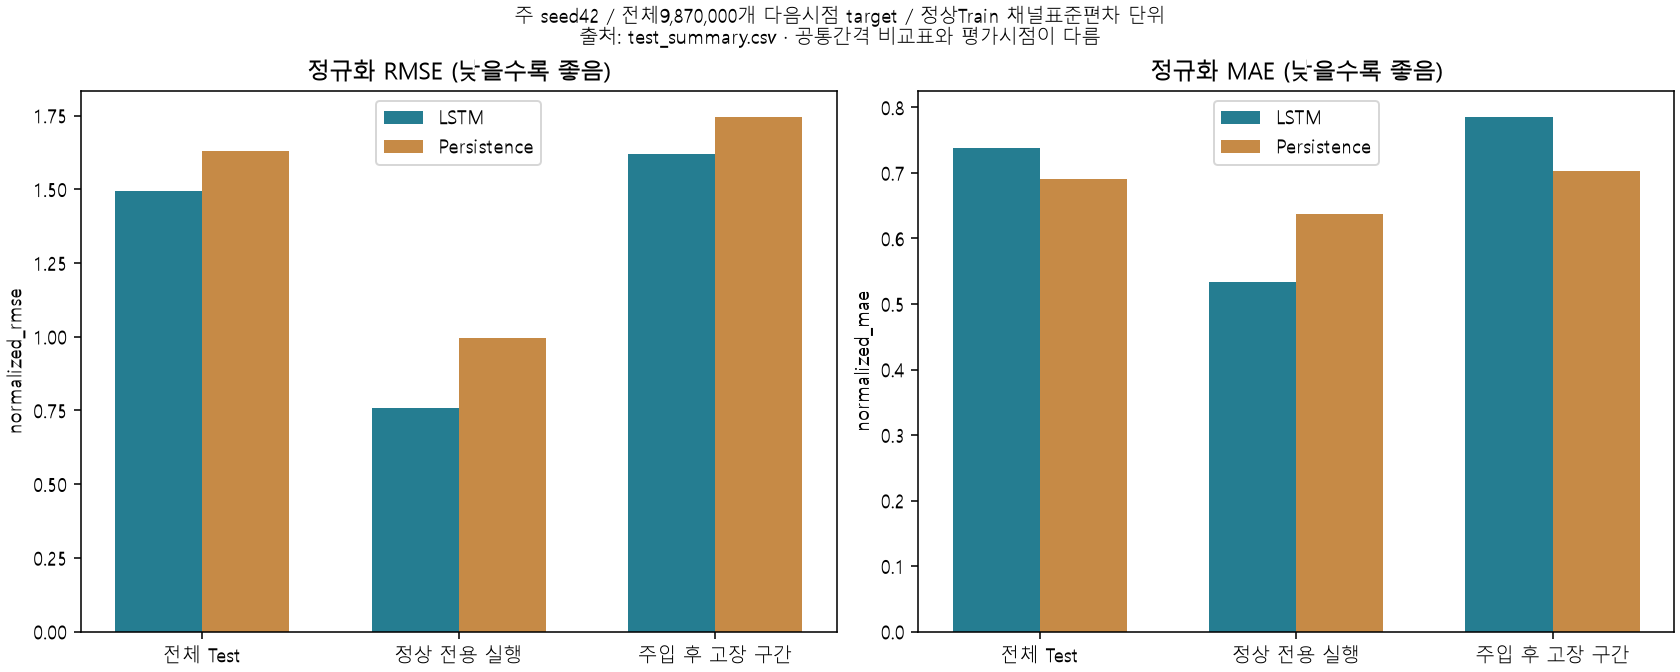

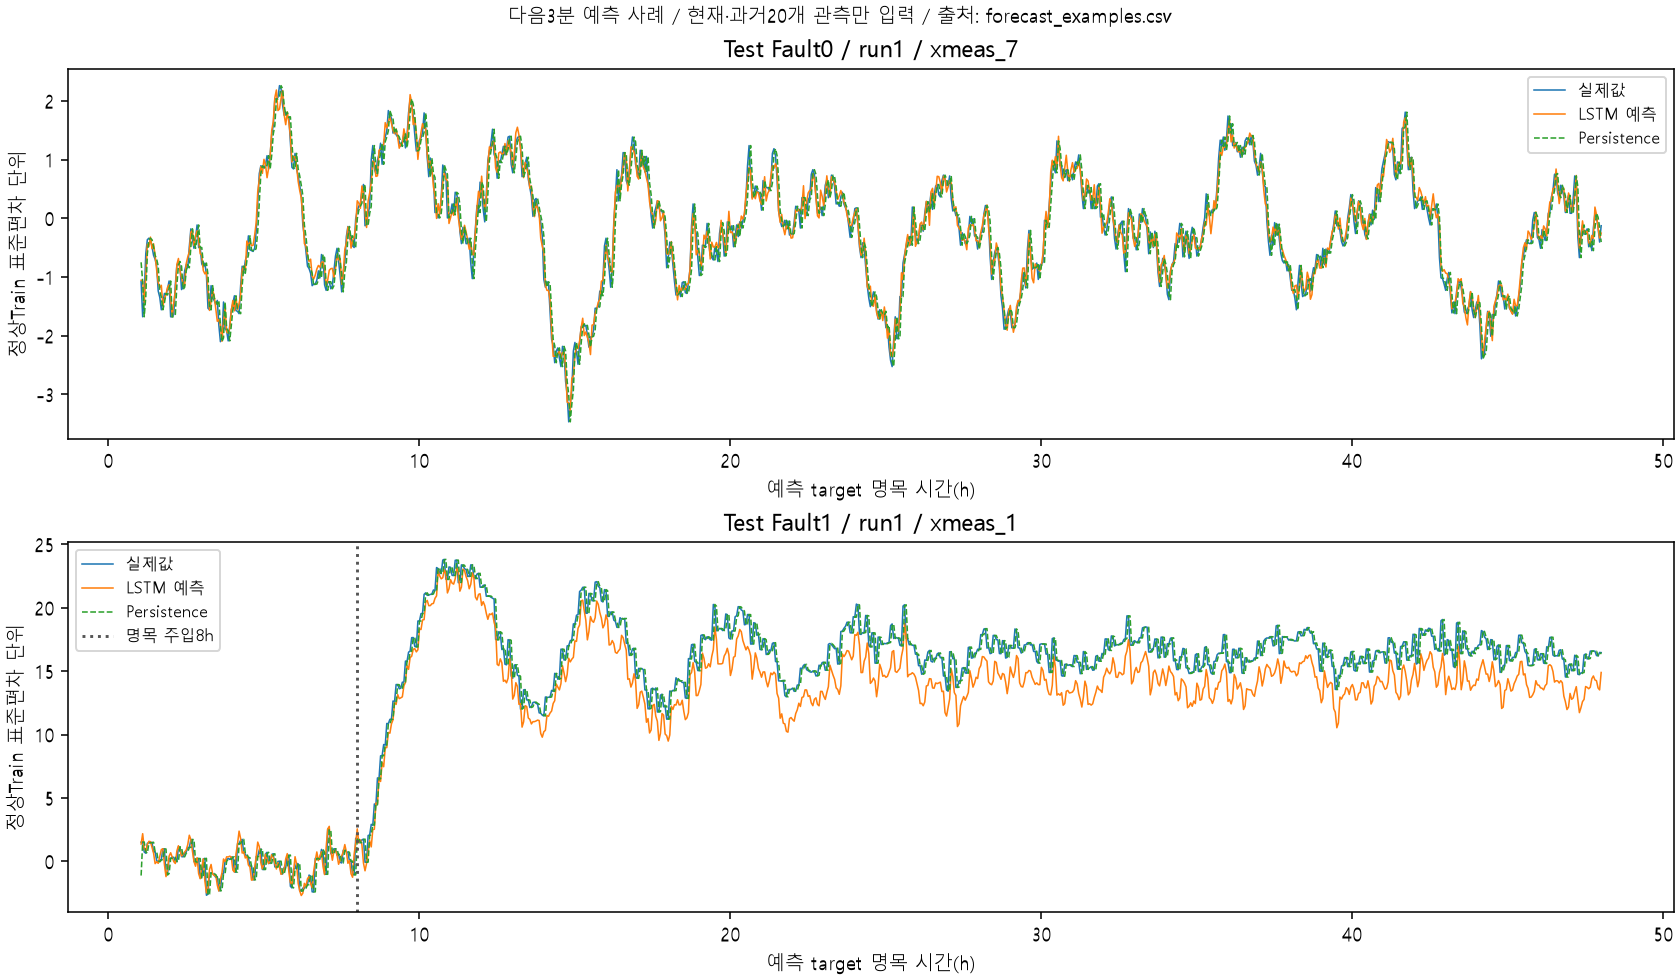

In [11]:
forecasts = read(F, 'test_summary.csv')
dense = forecasts[(forecasts.seed==42)&(forecasts['mode']=='dense')]
display(dense[['model','cohort','target_rows','normalized_rmse','normalized_mae']]
        .rename(columns={'model':'모델','cohort':'평가 구간','target_rows':'예측 정답 시점 수',
                         'normalized_rmse':'정규화 RMSE','normalized_mae':'정규화 MAE'}))
picture(F, 'lstm_vs_persistence.png')
picture(F, 'forecast_examples.png')

**결과를 한쪽 지표로만 판단하지 않습니다.** 전체 Test의 정규화 RMSE는 1.6301→1.4943으로 감소했지만 MAE는 0.6905→0.7378로 증가했습니다. 정상 전용 실행에서는 두 오차가 개선됐고, 고장 이후 구간에서는 MAE가 악화됐습니다. 정상만 학습한 모델의 고장 구간 예측은 학습 분포 밖의 성격이 있습니다.

LSTM 평가의 정답 시점은 9,870,000개입니다. 마지막 관측의 다음 정답이 없어서 제외하므로 CNN 분류 평가 9,880,500개와 다릅니다. 10시점 간격의 공통 평가(987,000개)와 전체 평가도 구분했습니다. 공통 시점에서는 MAE 개선 방향까지 달라져, 일부 표본만으로 전체 성능을 주장하면 안 됩니다. 상세 노트북에는 seed별 결과와 변수별 오차도 있습니다.

## 8. 실제로 무엇을 사용할 수 있나?

| 목적 | 사용 대상 | 입력 → 결과 |
|---|---|---|
| 정상인지 고장인지 판단 | 기존 CNN + 고정 경보 임계값 | 연속 20×52 → 정상/고장 확률·경보 |
| 어떤 고장인지 분석 | 기존 CNN의 21개 출력 + 추가 진단 평가 코드 | 클래스 확률 → 유형 후보·3연속 확정 유형·성능표 |
| 센서 입력 손실 영향을 연구 | 입력 유효성 마스크 평가 | 누락 조건 → 전체/조건부 검출률·진단률 |
| 다음 센서값을 예측 | 별도 LSTM `predict.py` | 연속 관측 20개 이상 → 다음 시점의 52변수 |

LSTM 사용 예(TEP 프로젝트 루트에서 실행, 여기서는 실행하지 않음):

```powershell
python experiments/next_step_forecasting/predict.py --input one_run.csv --output next_step_predictions.csv
```

CSV에는 52개 원 센서 열이 필요합니다. 한 번에 한 실행·한 시나리오의 연속 관측을 전달하며, 결측값·부족한 이력·끊어진 sample 번호는 거부합니다. 실제 사용 환경에는 프로젝트 의존성을 설치해야 합니다. 이 종합 노트북은 결과 열람용이며 배포용 실시간 화면이나 통합 하이브리드 모델을 새로 만드는 작업은 포함하지 않습니다.

### 8-1. 모델별 Accuracy는 어디서 확인하나?

Accuracy는 **정답과 예측이 일치하는 시점 수 / 평가한 전체 시점 수**입니다. 혼동행렬에서는 `np.trace(cm) / cm.sum()`으로 계산합니다. 정상/고장 2종 정확도와 정상 포함 21종 정확도는 서로 다른 지표입니다. 98.51%는 실행 단위 검출률이며 시점 단위 Accuracy가 아닙니다.

아래 첫 표는 최종 CNN의 **전체 유효 Test 시점** 결과입니다. 두 번째 표는 과거 모델 비교에서 저장한 **10시점 간격 공통 평가 집합**의 혼동행렬을 읽어 계산합니다. 모델별 Validation 선택 구성과 학습 seed 3개의 평균±표준편차입니다. 공통 평가와 전체 평가의 숫자는 평가 시점이 다르므로 직접 섞지 않습니다.

고장 조건부 20종 Accuracy는 실제 고장 구간에서 정상 여부를 알고 유형만 구분한 값입니다. 별도 LSTM 다음값 예측은 연속값 회귀이므로 분류 Accuracy를 적용하지 않고 RMSE·MAE로 확인합니다. 아래의 LSTM 분류기는 초기 모델 비교의 분류 모델이며 새 LSTM 공정 변수 예측기와 다릅니다.

In [12]:
cm_dense = np.load(ROOT/'reports/tables/phase2/primary_dense_confusion.npy')
def accuracies(cm):
    total = cm.sum()
    binary_correct = cm[0,0] + cm[1:,1:].sum()
    return float(binary_correct/total), float(np.trace(cm)/total)
binary_acc, multiclass_acc = accuracies(cm_dense)
display(pd.DataFrame([
 ['최종 CNN 정상/고장 2종', binary_acc, int(cm_dense.sum())],
 ['최종 CNN 임계값 적용 21종', multiclass_acc, int(cm_dense.sum())],
 ['최종 CNN 단순 argmax 21종', v['classification_metrics']['argmax21']['accuracy'], v['samples']],
 ['최종 CNN 고장 조건부 20종', v['classification_metrics']['conditional20']['accuracy'], v['post_fault_samples']]
],columns=['평가','Accuracy','시점 수']).style.format({'Accuracy':'{:.2%}','시점 수':'{:,.0f}'}).hide(axis='index'))

selected = pd.read_csv(ROOT/'reports/tables/phase2/model_performance_summary.csv')
rows = []
for r in selected.itertuples(index=False):
    for seed in [42,7,2026]:
        model_id = f'{r.model}_{r.features}_{r.weight}_s{seed}'
        cm = np.load(ROOT/f'reports/tables/phase2/{model_id}_confusion.npy')
        a2,a21 = accuracies(cm)
        rows.append({'model':r.model,'features':r.features,'weight':r.weight,'seed':seed,
                     'binary_accuracy':a2,'class21_accuracy':a21,'samples':int(cm.sum())})
all_accuracy = pd.DataFrame(rows)
accuracy_summary = all_accuracy.groupby(['model','features','weight'],sort=False).agg(
    binary_accuracy_mean=('binary_accuracy','mean'),binary_accuracy_sd=('binary_accuracy','std'),
    class21_accuracy_mean=('class21_accuracy','mean'),class21_accuracy_sd=('class21_accuracy','std'),
    seeds=('seed','count'),samples=('samples','first')).reset_index()
display(accuracy_summary.style.format({c:'{:.2%}' for c in accuracy_summary.columns if 'accuracy' in c}).hide(axis='index'))
all_accuracy.to_csv(ROOT/'reports/model_extension_overview/accuracy_by_model_seed.csv',index=False)
accuracy_summary.to_csv(ROOT/'reports/model_extension_overview/accuracy_model_summary.csv',index=False)

평가,Accuracy,시점 수
최종 CNN 정상/고장 2종,89.05%,"9,880,500"
최종 CNN 임계값 적용 21종,87.32%,"9,880,500"
최종 CNN 단순 argmax 21종,83.11%,"9,880,500"
최종 CNN 고장 조건부 20종,91.36%,"8,000,000"


model,features,weight,binary_accuracy_mean,binary_accuracy_sd,class21_accuracy_mean,class21_accuracy_sd,seeds,samples
CNN1D,Temporal,balanced,89.95%,0.38%,88.12%,0.26%,3,997500
LSTM,Temporal,balanced,89.69%,0.70%,87.69%,0.67%,3,997500
GRU,Temporal,balanced,89.62%,0.45%,87.51%,0.37%,3,997500
XGBoost,Statistical,natural,86.09%,0.05%,84.33%,0.04%,3,997500
LogisticRegression,Statistical,balanced,84.32%,0.00%,81.60%,0.00%,3,997500
RandomForest,Statistical,natural,84.21%,0.12%,82.09%,0.09%,3,997500
XGBoost,Current,balanced,79.38%,0.21%,76.20%,0.19%,3,997500
RandomForest,Current,natural,73.30%,0.34%,69.65%,0.36%,3,997500
LogisticRegression,Current,natural,64.65%,0.00%,56.71%,0.00%,3,997500


## 9. 검증과 연구의 한계

- 기존 CNN의 시점별 결과와 이벤트 검출을 재현했고, 21개 클래스의 기존 Precision/Recall/F1/support와도 대조했습니다.
- 잘못된 초기 유형 후 정답 진단, 유형이 바뀌는 3연속 고장 검출, 입력 불가 시 진단 금지 등을 검사했습니다.
- LSTM은 정상 Train만으로 scaler를 맞췄으며 미래 관측을 바꿔도 과거 예측이 바뀌지 않는지 확인했습니다.
- 원래의 모델과 노트북 파일 보존 검사를 통과했습니다. 두 상세 노트북은 오류 없이 실행됐습니다.
- 기존에 사용한 Test의 후속 분석입니다. 독립적인 새 외부 검증 데이터로 일반화 성능을 검증한 결과는 아닙니다.
- 센서 누락 중 재학습하지 않았으므로 결측이 학습에 미치는 영향은 다루지 않습니다. 원본 예측의 마스크 필터링은 적용 범위 손실 연구입니다.
- 진단 성공은 관측 기간 내 한 번의 정답 확정을 뜻합니다. 최초 정확도와 제한 시간 내 진단률을 함께 읽어야 합니다.
- CNN은 그대로이므로 ‘새 CNN이 더 좋아졌다’고 결론내릴 수 없습니다. LSTM도 전체 RMSE 개선과 MAE 악화가 함께 나타났습니다.

In [13]:
diagnosis_checks = json.loads((D/'sources/test_results.json').read_text(encoding='utf-8'))
forecast_checks = json.loads((F/'api_checks.json').read_text(encoding='utf-8'))
assert v['all_reference_results_match'] and v['no_retraining'] and v['no_threshold_selection']
assert diagnosis_checks['passed'] and forecast_checks['passed']
assert not diagnosis_checks['changed_files']
display(pd.DataFrame([
 ['CNN 기존 결과 재현', v['all_reference_results_match']],
 ['CNN 재학습 없음', v['no_retraining']],
 ['경보 임계값 재선정 없음', v['no_threshold_selection']],
 ['진단 평가 로직 검사', diagnosis_checks['passed']],
 ['LSTM 입력·미래 정보 누출 검사', forecast_checks['passed']],
 ['보호 대상 기존 파일 변경', len(diagnosis_checks['changed_files'])]
], columns=['검증 항목','결과']).style.hide(axis='index'))

검증 항목,결과
CNN 기존 결과 재현,True
CNN 재학습 없음,True
경보 임계값 재선정 없음,True
진단 평가 로직 검사,True
LSTM 입력·미래 정보 누출 검사,True
보호 대상 기존 파일 변경,0


## 10. 상세 산출물 찾아보기

| 자료 | 프로젝트 루트 기준 경로 |
|---|---|
| 이전 전체 연구 과정 | `notebooks/14_TEP_종합_연구_노트북.ipynb` |
| 고장 유형·가용성 상세 분석 | `experiments/fault_type_validation/15_fault_type_validation.ipynb` |
| LSTM 학습·예측 상세 분석 | `experiments/next_step_forecasting/16_next_step_forecasting.ipynb` |
| 진단 평가 코드 / 설명 | `experiments/fault_type_validation/evaluate.py`, `README.md` |
| LSTM 추론 코드 / 설명 | `experiments/next_step_forecasting/predict.py`, `README.md` |
| 유형·가용성 분석 보고서 | `reports/fault_type_validation/final_report.md` |
| LSTM 예측 보고서 | `reports/next_step_forecasting/final_report.md` |
| 입력 가용성 원 실험 | `experiments/sensor_availability/11~13번 노트북`, `reports/sensor_availability/final_report.md` |

[참고 GitHub](https://github.com/min3237/tep-fault-diagnosis-dl)의 유형별 평가와 다음 시점 예측 아이디어를 참고했습니다. 데이터 구성과 평가 과제가 달라 해당 저장소의 점수와 직접 우열을 비교하지 않았으며, 예측값을 분류 입력에 넣는 구조를 동일하게 재현한 것도 아닙니다.

**현재 제공하는 변화는 ‘기존 CNN의 유형 진단을 더 명확하게 평가할 수 있게 된 것’, ‘입력 가용성과 진단 범위의 관계를 확인할 수 있게 된 것’, ‘독립 LSTM으로 다음 공정 변수값을 예측할 수 있게 된 것’입니다.**